# GP-v2 corpus — composition, balance, and what it bought

**GP-v2 trained and shipped 2026-08-08:** these 1,744.8 h took the frozen parliament test set
from v1's 5.29 % WER to **4.12 %** with *nothing but the data changed* — same architecture,
tokenizer, schedule and split. Section 5 reads the decode results off disk.

**Re-runnable**: reads the cut manifests on disk (axes still being produced show as *pending*),
so *Run All* refreshes the picture as the campaign progresses. Method + rationale:
[`BG_ASR_DATA_PIPELINE.md`](BG_ASR_DATA_PIPELINE.md) (preprocessing per axis, quality gates,
the 0.5–2× register-balance rule and the mux-weights lever) ·
[`BG_ASR_BENCHMARK.md`](BG_ASR_BENCHMARK.md) (full results + caveats).

## 1 · Scan the axis manifests

In [1]:
from pathlib import Path
from lhotse import CutSet

REPO = Path.home() / "WORK/OmniVoice"

def hours_split(path, splitter=None):
    # total hours (and optional sub-splits by cut-id prefix) of a cuts manifest
    if not path.exists():
        return None
    tot, sub = 0.0, {}
    for c in CutSet.from_file(path):
        d = c.duration / 3600
        tot += d
        if splitter:
            sub[splitter(c.id)] = sub.get(splitter(c.id), 0.0) + d
    return tot, sub

# v1 gold mixes two registers -> split by cut-id prefix
v1 = hours_split(REPO/"data/fbank/bg_cuts_train.jsonl.gz",
                 lambda cid: "parliament" if cid.startswith("plsten") else "audiobook")

AXES = [  # (label, register, manifest, hours)
    ("v1 parliament (gold)",   "parliament",     "bg_cuts_train.jsonl.gz [plsten]",
        None if v1 is None else v1[1].get("parliament", 0.0)),
    ("v1 AB400 audiobook (gold)", "read literary", "bg_cuts_train.jsonl.gz [rest]",
        None if v1 is None else v1[1].get("audiobook", 0.0)),
    ("parliament recovery (gold)", "parliament",  "fbank_reseg/bg_cuts_train.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank_reseg/bg_cuts_train.jsonl.gz"))),
    ("BNR archive (weak)",     "archival radio", "bg_cuts_bnr.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank/bg_cuts_bnr.jsonl.gz"))),
    ("DnevenRed (weak+agree)", "conversational", "bg_cuts_ytdr.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank/bg_cuts_ytdr.jsonl.gz"))),
    ("Bloomberg BG (weak+agree)", "broadcast news", "bg_cuts_ytbb.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank/bg_cuts_ytbb.jsonl.gz"))),
    ("Govori Internet (weak+agree)", "conversational", "bg_cuts_ytgi.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank/bg_cuts_ytgi.jsonl.gz"))),
    ("FLEURS train (gold-read)", "read modern",   "bg_cuts_fleurs_train.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank/bg_cuts_fleurs_train.jsonl.gz"))),
    ("CommonVoice train (gold-read)", "read modern", "bg_cuts_cv_train.jsonl.gz",
        (lambda r: r and r[0])(hours_split(REPO/"data/fbank/bg_cuts_cv_train.jsonl.gz"))),
]

present = [(l, reg, h) for l, reg, _, h in AXES if h]
pending = [(l, reg) for l, reg, _, h in AXES if not h]
tot = sum(h for _, _, h in present)
print(f"{'axis':34s} {'register':16s} {'hours':>8s} {'share':>7s}")
for l, reg, h in present:
    print(f"{l:34s} {reg:16s} {h:8.1f} {100*h/tot:6.1f}%")
print(f"{'TOTAL (present axes)':34s} {'':16s} {tot:8.1f}")
for l, reg in pending:
    print(f"{l:34s} {reg:16s} {'pending':>8s}")

axis                               register            hours   share
v1 parliament (gold)               parliament          238.9   13.7%
v1 AB400 audiobook (gold)          read literary       410.3   23.5%
parliament recovery (gold)         parliament          334.4   19.2%
BNR archive (weak)                 archival radio      102.9    5.9%
DnevenRed (weak+agree)             conversational      292.6   16.8%
Bloomberg BG (weak+agree)          broadcast news      135.1    7.7%
Govori Internet (weak+agree)       conversational      214.0   12.3%
FLEURS train (gold-read)           read modern           9.5    0.5%
CommonVoice train (gold-read)      read modern           7.0    0.4%
TOTAL (present axes)                                  1744.8


## 2 · Composition chart

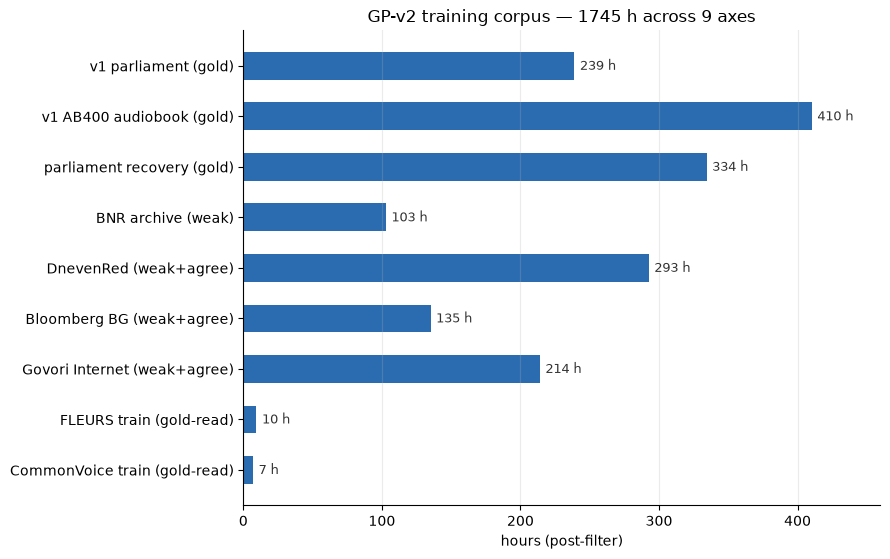

In [2]:
import matplotlib.pyplot as plt

labels = [l for l, _, _ in present][::-1]
vals   = [h for _, _, h in present][::-1]
fig, ax = plt.subplots(figsize=(9, 0.5*len(labels)+1.2))
bars = ax.barh(labels, vals, color="#2b6cb0", height=0.55)
for b, v in zip(bars, vals):                       # selective direct labels, text in ink not series color
    ax.text(b.get_width()+4, b.get_y()+b.get_height()/2, f"{v:.0f} h",
            va="center", fontsize=9, color="#333333")
ax.set_xlabel("hours (post-filter)")
ax.set_title(f"GP-v2 training corpus — {tot:.0f} h across {len(present)} axes"
             + (f"  ({len(pending)} pending)" if pending else ""))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)                      # recessive grid
ax.margins(x=0.12)
fig.tight_layout()
fig.savefig(Path.home()/"WORK/OmniVoice/docs/bg_asr_corpus.png", dpi=110)
plt.show()

## 3 · Register balance vs the 0.5–2× band

In [3]:
reg_h = {}
for _, reg, h in present:
    reg_h[reg] = reg_h.get(reg, 0.0) + h
mean = sum(reg_h.values())/len(reg_h)
print(f"{'register':16s} {'hours':>8s} {'share':>7s}   vs-mean")
for reg, h in sorted(reg_h.items(), key=lambda x: -x[1]):
    r = h/mean
    flag = "OK" if 0.5 <= r <= 2.0 else "OUT-OF-BAND"
    print(f"{reg:16s} {h:8.1f} {100*h/tot:6.1f}%   {r:4.1f}x  {flag}")
mx, mn = max(reg_h.values()), min(reg_h.values())
print(f"\nmax/min register spread: {mx/mn:.1f}x  (guideline: keep registers within ~0.5-2x of "
      f"each other; GP-v2 keeps the NATURAL mix for data-effect attribution — rebalance, if "
      f"eval demands it, via train-time mux weights, not re-merging)")

register            hours   share   vs-mean
parliament          573.3   32.9%    2.0x  OK
conversational      506.7   29.0%    1.7x  OK
read literary       410.3   23.5%    1.4x  OK
broadcast news      135.1    7.7%    0.5x  OUT-OF-BAND
archival radio      102.9    5.9%    0.4x  OUT-OF-BAND
read modern          16.5    0.9%    0.1x  OUT-OF-BAND

max/min register spread: 34.7x  (guideline: keep registers within ~0.5-2x of each other; GP-v2 keeps the NATURAL mix for data-effect attribution — rebalance, if eval demands it, via train-time mux weights, not re-merging)


## 4 · The rebalancing lever (GP-v3, if needed)

*Post-GP-v2 note:* the three out-of-band registers above did **not** obviously cost us —
GP-v2's weakest measured sets are the read-modern ones (FLEURS/CV), which are also the
smallest axes (0.9 % of the corpus), so the lever below is aimed there first. But no register
is measured on unseen audio yet, so treat the weights as a hypothesis to test, not a fix to
apply blind — see the caveats in section 5.

In [4]:
# Example: weights that would sample registers toward uniform shares WITHOUT duplicating data.
# (Illustrative — wire into the datamodule only if GP-v2's eval shows an under-served register.)
target = {reg: 1/len(reg_h) for reg in reg_h}           # uniform target shares
w = {reg: target[reg]/(h/tot) for reg, h in reg_h.items()}
print("register            natural-share  ->  mux weight (relative)")
for reg in sorted(w, key=lambda r: -reg_h[r]):
    print(f"  {reg:16s} {100*reg_h[reg]/tot:6.1f}%          {w[reg]:.2f}")
print("\nusage: CutSet.mux(*axis_cutsets, weights=[...], stop_early=False)  # lazy, no disk cost")

register            natural-share  ->  mux weight (relative)
  parliament         32.9%          0.51
  conversational     29.0%          0.57
  read literary      23.5%          0.71
  broadcast news      7.7%          2.15
  archival radio      5.9%          2.83
  read modern         0.9%          17.60

usage: CutSet.mux(*axis_cutsets, weights=[...], stop_early=False)  # lazy, no disk cost


## 5 · What the corpus bought — GP-v2 decode results

Reads every `wer-summary-*.txt` under `zipformer/exp_gp/` (epoch 30, avg 5), so this refreshes
as new decodes land. v1's published numbers are inlined as the baseline.

In [5]:
import re

EXP = Path.home() / "icefall/egs/bg_parliament/ASR/zipformer/exp_gp"
SETS = ["dev", "test", "fleurs", "cv"]          # parliament holdouts, then the read-modern pair
SHIPPED = {"GP-v2": "beam 4", "v1": "LG @ 0.2"}  # each model's chosen system differs

def wer_table(exp):
    # {system -> {eval_set -> WER}}; the LG sweep yields one system per ngram-lm-scale
    out = {}
    for f in sorted(exp.glob("*/wer-summary-*.txt")):
        m = re.match(r"wer-summary-(.+?)-epoch-", f.name)
        if not m:
            continue
        eset = m.group(1).replace("bg_cuts_", "")
        scale = re.search(r"ngram-lm-scale-([0-9.]+)", f.name)
        sysname = {"greedy_search": "greedy",
                   "modified_beam_search": "beam 4",
                   "fast_beam_search_nbest_LG": "LG"}.get(f.parent.name, f.parent.name)
        if scale:
            sysname += f" @ {scale.group(1)}"
        wers = [float(l.split("\t")[1]) for l in f.read_text().splitlines()[1:] if "\t" in l]
        if wers:
            out.setdefault(sysname, {})[eset] = min(wers)
    return out

V1 = {"greedy":   {"dev": 5.29, "test": 5.52, "fleurs": 20.35, "cv": 22.27},   # published v1
      "beam 4":   {"dev": 5.19, "test": 5.46},
      "LG @ 0.2": {"dev": 5.14, "test": 5.29}}

def show(title, tbl, model):
    hdr = f"{'system':16s}" + "".join(f"{s:>9s}" for s in SETS) + "   "
    print(f"{title}\n{hdr}\n" + "-" * (len(hdr) + 6))
    for sysname in sorted(tbl, key=lambda k: (k.startswith("LG"), k)):
        row = tbl[sysname]
        mark = "  <- ships" if sysname == SHIPPED[model] else ""
        print(f"{sysname:16s}"
              + "".join(f"{row[s]:9.2f}" if s in row else f"{'—':>9s}" for s in SETS) + mark)

tbl = wer_table(EXP)
show("GP-v2 (1,744.8 h) — WER %, epoch 30 / avg 5", tbl, "GP-v2")
print()
show("v1 (649 h) baseline — same frozen split", V1, "v1")

best_v2 = tbl.get(SHIPPED["GP-v2"], {}).get("test")
best_v1 = V1[SHIPPED["v1"]]["test"]
if best_v2:
    print(f"\nfrozen parliament test: {best_v1} -> {best_v2:.2f}  "
          f"({100*(best_v1-best_v2)/best_v1:.0f}% relative), from data alone")

GP-v2 (1,744.8 h) — WER %, epoch 30 / avg 5
system                dev     test   fleurs       cv   
-------------------------------------------------------------
beam 4               3.94     4.12     9.84     8.69  <- ships
greedy               4.00        —    10.01     9.01
LG @ 0.01            4.10        —        —        —
LG @ 0.05            4.05        —        —        —
LG @ 0.1             3.99        —    11.13    11.20
LG @ 0.2             3.99        —    12.80    11.58
LG @ 0.3             4.54        —        —        —

v1 (649 h) baseline — same frozen split
system                dev     test   fleurs       cv   
-------------------------------------------------------------
beam 4               5.19     5.46        —        —
greedy               5.29     5.52    20.35    22.27
LG @ 0.2             5.14     5.29        —        —  <- ships

frozen parliament test: 5.29 -> 4.12  (22% relative), from data alone


### How to read this table

- **Only the parliament row is unambiguous.** FLEURS and CV *train* splits are in the corpus
  above (the two smallest axes), so their test WERs measure held-out-split, **in-corpus**
  performance — domain adaptation, not generalization. The v1 → GP-v2 movement on those two
  sets (20.35 → 9.84, 22.27 → 8.69) conflates both effects and must not be quoted as a
  generalization gain. Verified *not* leakage: zero cut-id, recording-id and sentence-text
  overlap between train and test for both corpora.
- **The external LM lost its job.** `LG` was v1's best system; on GP-v2 it loses on every set
  even after being rebuilt on this corpus's own text. Rebuilding halved CV's OOV
  (7.90 → 4.06 %) and CV's WER still got *worse* — coverage improved, the phrasing prior
  (parliament/audiobook/YouTube-dominated) did not. Shipped system is LM-free.
- **Still unmeasured:** every register in the chart above, on audio nobody trained on. A fresh
  self-recorded set is the next thing to build — until it exists, 4.12 % on parliament is the
  only number this corpus can honestly claim.